# L08 -  Notch-Filter (Lösung zu Aufgabe 08)

Für die Lösung MATLAB `*.m` Dateiformat bitte [hier klicken](./l08.m).

Benoetigte `m`-Datei:  [`lnotchdesign.m`](./lnotchdesign.m)

## Teilaufgabe b: Dimensionierung und Frequenzgang

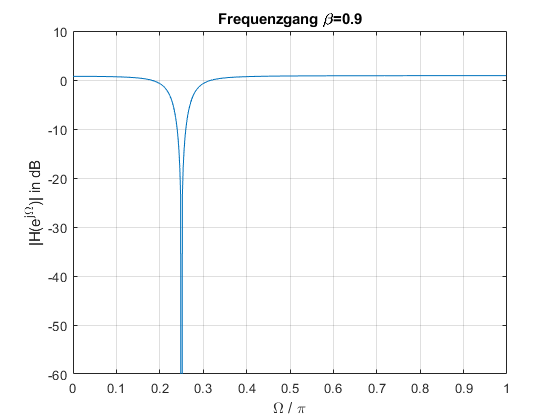

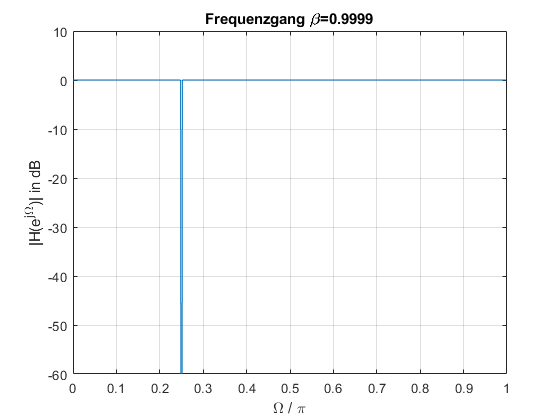

In [1]:
Omega0 = pi/4;

for beta = [0.9 0.9999]
    [a,b] = lnotchdesign(Omega0,beta);
    [H,Omega] = freqz(b,a);

    figure;
    plot(Omega/pi,20*log10(abs(H)));
    title(['Frequenzgang \beta=',num2str(beta)]);
    xlabel('\Omega / \pi');
    ylabel('|H(e^{j\Omega})| in dB');
    set(gca,'ylim',[-60 10]);
    grid on;
end

### Teilaufgabe c:  Audiodemonstration

In [2]:
fa = 8000;     % Abtastfrequenz
fsinus = 1000; % Frequenz des Sinus-Signals
dauer = 5;     % Dauer des Signals in Sekunden
N = fa*dauer;  % Anzahl der Abtastwerte

% Erzeugen des Rausch+Sinus-Signals
x1 = 0.5*sin(2*pi*fsinus/fa*(1:N)');
x2 = (rand(N,1)-0.5)/2;
x = x1+x2;

disp('sie hoeren: x(k) ungefiltert'); 
sound(x,fa);

beta = 0.9; 
Omega0 = 2*pi*fsinus/fa;      
[a,b] = lnotchdesign(Omega0,beta); 
y = filter(b,a,x);

disp(['sie hoeren: y(k) gefiltert beta=',num2str(beta)]); 
sound(y,fa);

sie hoeren: x(k) ungefiltert
sie hoeren: y(k) gefiltert beta=0.9



## Teilaufgabe d: Audiodemonstration, Laenge der Impulsantwort

sie hoeren: x(k) ungefiltert
sie hoeren: x(k) gefiltert beta=0.9999



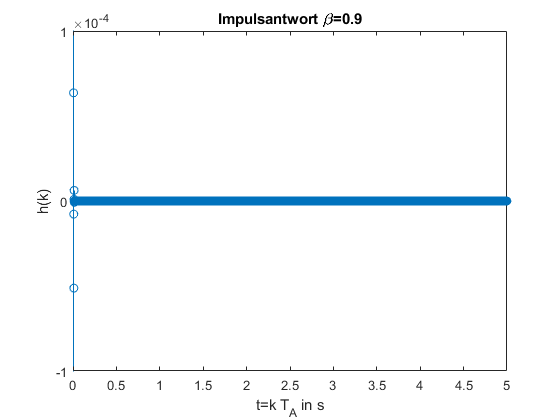

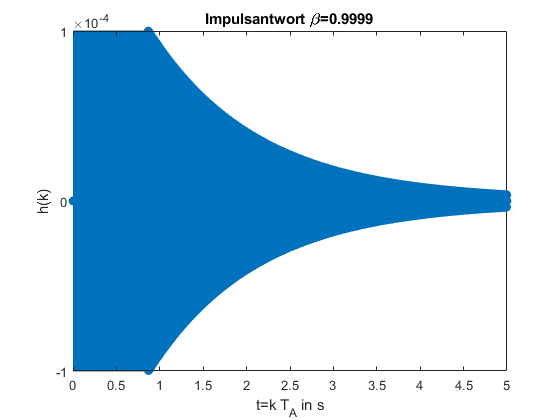

In [3]:
% #####  Teilaufgabe d:  Audiodemonstration, Laenge der Impulsantwort  #####
disp('sie hoeren: x(k) ungefiltert'); 
sound(x,fa);

beta = 0.9999;
[a,b] = lnotchdesign(Omega0,beta); 
y = filter(b,a,x);

disp(['sie hoeren: x(k) gefiltert beta=',num2str(beta)]); 
sound(y,fa);

for beta = [0.9 0.9999]
    [a,b] = lnotchdesign(Omega0,beta);

    [h,t] = impz(b,a,N,fa);

    % zur Darstellung weniger Stuetzstellen verwenden
    t = t(1:10:length(h)); 
    h = h(1:10:length(h));

    % # grafische Ausgabe # %
    figure;
    stem(t,h);
    axis([0 dauer -1e-4 1e-4]);
    title(['Impulsantwort \beta=',num2str(beta)]); 
    xlabel('t=k T_A in s'); 
    ylabel('h(k)');
end

## Teilaufgabe e: Radiosignal

In [4]:
% #####  Teilaufgabe e:  Radiosignal  #####
[x,fa] = audioread('l936.28_kHz_25.04.2001_23_17.wav');  

f0 = 345;
beta = 0.9; 
Omega0 = 2*pi*f0/fa;      
[a,b] = lnotchdesign(Omega0,beta); 
y = filter(b,a,x);
y = y/max(abs(y)); % Skalierung zur Ausgabe
audiowrite('l936.28_kHz_25.04.2001_23_17.result.wav',y,fa);